In [ ]:
import itertools
import random
import pandas as pd


In [ ]:
num_attributes = 4
all_objects = list(itertools.product([0, 1], repeat=num_attributes))

print(all_objects)

print("Total number of objects:", len(all_objects))


[(0, 0, 0, 0), (0, 0, 0, 1), (0, 0, 1, 0), (0, 0, 1, 1), (0, 1, 0, 0), (0, 1, 0, 1), (0, 1, 1, 0), (0, 1, 1, 1), (1, 0, 0, 0), (1, 0, 0, 1), (1, 0, 1, 0), (1, 0, 1, 1), (1, 1, 0, 0), (1, 1, 0, 1), (1, 1, 1, 0), (1, 1, 1, 1)]
Total number of objects: 16


In [ ]:
def hidden_rule(obj):
    return obj[0] == 1 and obj[1] == 1

print(hidden_rule((1, 1, 0, 0)))
print(hidden_rule((1, 0, 1, 1)))


True
False


In [ ]:
labels = [hidden_rule(obj) for obj in all_objects]
print(labels)


[False, False, False, False, False, False, False, False, False, False, False, False, True, True, True, True]


In [ ]:
df = pd.DataFrame(all_objects, columns=["A", "B", "C", "D"])
df["Category"] = labels
display(df)


,A,B,C,D,Category
0,0,0,0,0,False
1,0,0,0,1,False
2,0,0,1,0,False
3,0,0,1,1,False
4,0,1,0,0,False
5,0,1,0,1,False
6,0,1,1,0,False
7,0,1,1,1,False
8,1,0,0,0,False
9,1,0,0,1,False


In [ ]:
random.seed(42)
train_indices = random.sample(range(len(all_objects)), 6)

print(train_indices)


[3, 0, 11, 4, 15, 13]


In [ ]:
training_df = df.iloc[train_indices]

display(training_df)


,A,B,C,D,Category
3,0,0,1,1,False
0,0,0,0,0,False
11,1,0,1,1,False
4,0,1,0,0,False
15,1,1,1,1,True
13,1,1,0,1,True


In [ ]:
def alternative_rule(obj):
    return obj[1] == 1 and obj[3] == 1

In [ ]:
test_object = (0, 1, 0, 1)
print("Hidden rule:", hidden_rule(test_object))
print("Alternative rule:", alternative_rule(test_object))


Hidden rule: False
Alternative rule: True


In [ ]:
test_object = (0, 1, 0, 1)

print("Hidden rule:", hidden_rule(test_object))
print("Alternative rule:", alternative_rule(test_object))


Hidden rule: False
Alternative rule: True


In [ ]:
for index in train_indices:
    obj = all_objects[index]
    print(index, hidden_rule(obj), alternative_rule(obj))


3 False False
0 False False
11 False False
4 False False
15 True True
13 True True


In [ ]:
agreements = []

for index in train_indices:
    obj = all_objects[index]
    agreements.append(hidden_rule(obj) == alternative_rule(obj))

print("Do both rules agree on all training objects?", all(agreements))


Do both rules agree on all training objects? True


In [ ]:
disagreements = []

for obj in all_objects:
    if hidden_rule(obj) != alternative_rule(obj):
        disagreements.append(obj)

print(disagreements)


[(0, 1, 0, 1), (0, 1, 1, 1), (1, 1, 0, 0), (1, 1, 1, 0)]


In [ ]:
informative_obj = disagreements[0]
observed_label = hidden_rule(informative_obj)

print("Chosen object:", informative_obj)
print("Correct category:", observed_label)
print("Alternative rule predicts:", alternative_rule(informative_obj))


Chosen object: (0, 1, 0, 1)
Correct category: False
Alternative rule predicts: True


In [ ]:
new_index = all_objects.index(informative_obj)
print(new_index)


updated_train_indices = train_indices + [new_index]
print(updated_train_indices)



5
[3, 0, 11, 4, 15, 13, 5]


In [ ]:
alternative_matches = []

for index in updated_train_indices:
    obj = all_objects[index]
    alternative_matches.append(alternative_rule(obj) == labels[index])

print(alternative_matches)


[True, True, True, True, True, True, False]


In [ ]:
print("Does the alternative rule still fit all examples?", all(alternative_matches))


Does the alternative rule still fit all examples? False


In [ ]:
attribute_pairs = list(itertools.combinations(range(num_attributes), 2))

print(attribute_pairs)


[(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]


In [ ]:
candidate_rules = []

for pair in attribute_pairs:
    for values in itertools.product([0, 1], repeat=2):
        candidate_rules.append((pair, values))


In [ ]:
print("Number of candidate rules:", len(candidate_rules))
print("First four rules:", candidate_rules[:4])


Number of candidate rules: 24
First four rules: [((0, 1), (0, 0)), ((0, 1), (0, 1)), ((0, 1), (1, 0)), ((0, 1), (1, 1))]


In [ ]:
def evaluate_rule(obj, rule):
    pair, values = rule
    return obj[pair[0]] == values[0] and obj[pair[1]] == values[1]

test_rule = ((0, 1), (1, 1))
test_object = (1, 1, 0, 0)

print(evaluate_rule(test_object, test_rule))


True


In [ ]:
consistent_rules = []

for rule in candidate_rules:
    matches = []

    for index in train_indices:
        obj = all_objects[index]
        matches.append(evaluate_rule(obj, rule) == labels[index])

    if all(matches):
        consistent_rules.append(rule)

print("Number of consistent rules:", len(consistent_rules))
print("Consistent rules:", consistent_rules)


Number of consistent rules: 2
Consistent rules: [((0, 1), (1, 1)), ((1, 3), (1, 1))]


In [ ]:

consistent_rules = []

for rule in candidate_rules:
    matches = []

    for index in train_indices:
        obj = all_objects[index]
        matches.append(evaluate_rule(obj, rule) == labels[index])

    if all(matches):
        consistent_rules.append(rule)

print(consistent_rules)
print("Number of consistent rules:", len(consistent_rules))


[((0, 1), (1, 1)), ((1, 3), (1, 1))]
Number of consistent rules: 2


In [ ]:
updated_consistent_rules = []

for rule in candidate_rules:
    matches = []

    for index in updated_train_indices:
        obj = all_objects[index]
        matches.append(evaluate_rule(obj, rule) == labels[index])

    if all(matches):
        updated_consistent_rules.append(rule)

print(updated_consistent_rules)
print("Remaining rules:", len(updated_consistent_rules))


[((0, 1), (1, 1))]
Remaining rules: 1


In [ ]:
true_rule = ((0, 1), (1, 1))

remaining_rule = updated_consistent_rules[0]

print("Original hidden rule:", true_rule)
print("Remaining candidate rule:", remaining_rule)
print("Did we identify the correct rule?", remaining_rule == true_rule)


Original hidden rule: ((0, 1), (1, 1))
Remaining candidate rule: ((0, 1), (1, 1))
Did we identify the correct rule? True


In [ ]:
def learn_rule(indices):
    for rule in reversed(candidate_rules):
        matches = []

        for index in indices:
            obj = all_objects[index]
            matches.append(evaluate_rule(obj, rule) == labels[index])

        if all(matches):
            return rule

    return None





In [ ]:
learned_six = learn_rule(train_indices)
learned_seven = learn_rule(updated_train_indices)

print("Rule learned from 6 examples:", learned_six)
print("Rule learned from 7 examples:", learned_seven)


Rule learned from 6 examples: ((1, 3), (1, 1))
Rule learned from 7 examples: ((0, 1), (1, 1))


In [ ]:
test_indices = []

for index in range(len(all_objects)):
    if index not in train_indices:
        test_indices.append(index)

print(test_indices)


[1, 2, 5, 6, 7, 8, 9, 10, 12, 14]


In [ ]:
fair_test_indices = []

for index in test_indices:
    if index not in updated_train_indices:
        fair_test_indices.append(index)

print(fair_test_indices)


[1, 2, 6, 7, 8, 9, 10, 12, 14]


In [ ]:
correct_six = 0
correct_seven = 0

for index in fair_test_indices:
    obj = all_objects[index]
    actual_label = labels[index]

    if evaluate_rule(obj, learned_six) == actual_label:
        correct_six += 1

    if evaluate_rule(obj, learned_seven) == actual_label:
        correct_seven += 1



accuracy_six = correct_six / len(fair_test_indices)
accuracy_seven = correct_seven / len(fair_test_indices)

print("Six-example learner:", correct_six, "out of", len(fair_test_indices))
print("Seven-example learner:", correct_seven, "out of", len(fair_test_indices))

print("Six-example accuracy:", round(accuracy_six * 100, 2), "%")
print("Seven-example accuracy:", round(accuracy_seven * 100, 2), "%")


Six-example learner: 6 out of 9
Seven-example learner: 9 out of 9
Six-example accuracy: 66.67 %
Seven-example accuracy: 100.0 %


In [ ]:
print("Six-example learner correct:", correct_six)
print("Seven-example learner correct:", correct_seven)
print("Number of test objects:", len(fair_test_indices))


Six-example learner correct: 6
Seven-example learner correct: 9
Number of test objects: 9


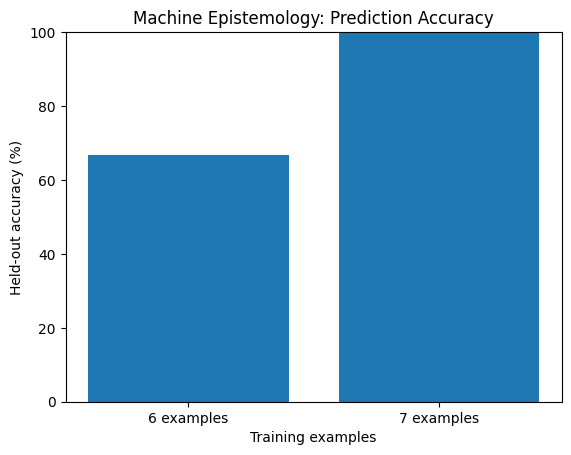

In [ ]:
import matplotlib.pyplot as plt

learners = ["6 examples", "7 examples"]
accuracies = [accuracy_six * 100, accuracy_seven * 100]


plt.bar(learners, accuracies)

plt.xlabel("Training examples")
plt.ylabel("Held-out accuracy (%)")
plt.title("Machine Epistemology: Prediction Accuracy")

plt.ylim(0, 100)

plt.savefig("machine_epistemology_experiment_1.png", dpi=300, bbox_inches="tight")

plt.show()


In [ ]:
results_df = pd.DataFrame({
    "Training examples": [6, 7],
    "Correct predictions": [correct_six, correct_seven],
    "Test objects": [len(fair_test_indices)] * 2,
    "Accuracy (%)": [accuracy_six * 100, accuracy_seven * 100]
})

display(results_df)

results_df.to_csv("machine_epistemology_experiment_1.csv", index=False)


,Training examples,Correct predictions,Test objects,Accuracy (%)
0,6,6,9,66.666667
1,7,9,9,100.000000


### Experiment 1 — Identifying Hidden Rules

**Objective:** Investigate whether a learning algorithm can identify the correct underlying rule from a limited number of training examples.

**Method:** I created an artificial environment containing 16 objects, each represented by four binary attributes. The hidden classification rule was A = 1 AND B = 1.

I generated 24 possible candidate rules and initially provided six randomly selected training examples.

**Results:**

- Six training examples left two possible rules consistent with the observations.
- One deliberately selected additional example reduced the number of consistent rules from two to one.
- The learner trained on six examples achieved 66.67% accuracy on nine unseen objects.
- The learner trained on seven examples achieved 100% accuracy on the same nine objects.

**Interpretation:** The experiment demonstrates that a learning algorithm can correctly classify all its training examples without identifying the original generating rule. An additional informative example helped distinguish the competing explanations.

**Limitations:** This experiment used a small artificial environment, a restricted set of candidate rules and a deliberately selected seventh example. The findings do not establish that similar improvements would occur across other datasets or that the algorithm has developed genuine conceptual understanding.